<a href="https://colab.research.google.com/github/eugeniomp216/Mini-Proyectos/blob/main/Calibrado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
from scipy.special import expit

In [ ]:
rng = np.random.default_rng(42)
n = 5000
X = rng.normal(size=(n, 3))
logit_real = (1.5 * X[:, 0]- 0.8 * X[:, 1]**2+ 0.7 * X[:, 0] * X[:, 2]) #Función que vamos a usar para generar la probabilidad
p_real = expit(logit_real) #Esta es la función sigmoide comprime cualquier número real en un rango estricto entre 0.0 y 1.0.
y = rng.binomial(1, p_real)

In [ ]:
from sklearn.metrics import (brier_score_loss,log_loss,roc_auc_score)

# Dado que p_real son las probabilidades perfectas, calculamos las métricas ideales
brier = brier_score_loss(y, p_real) #Mide el error cuadrático medio entre las probabilidades estimadas y los resultados observados.Cuanto menor sea el Brier Score, mejor. Su valor está entre 0 y 1.
loss = log_loss(y, p_real)#Mide la penalización por asignar probabilidades a los resultados observados
auc = roc_auc_score(y, p_real)#Mide la capacidad del modelo para ordenar correctamente los casos positivos por encima de los negativos.


### Evaluación de las probabilidades reales

Como conocemos el mecanismo generador de los datos, disponemos de las probabilidades teóricas de cada observación (`p_real`). Esto nos permite establecer una referencia ideal para evaluar posteriormente el modelo predictivo.

Utilizamos tres métricas:

- **Brier Score:** mide el error cuadrático medio de las probabilidades predichas respecto a los resultados observados.
- **Log Loss:** evalúa la calidad de las probabilidades penalizando especialmente las predicciones muy seguras que resultan incorrectas.
- **ROC-AUC:** mide la capacidad de discriminación del predictor, es decir, su habilidad para ordenar los casos positivos por encima de los negativos.

En este experimento, `p_real` representa las probabilidades verdaderas del proceso generador, por lo que sus métricas sirven como referencia para comparar los modelos que entrenaremos posteriormente.

Es importante señalar que estas métricas no serán necesariamente perfectas, ya que los resultados observados siguen siendo variables aleatorias.
Al calcular estas métricas con p_real estoy diciendo: Este es el mejor resultado posible. Cualquier modelo que entrene después debe compararse contra este número, no contra un 100% de perfección irreal.

In [ ]:
print(brier)
print(loss)
print(auc)

0.15867698870742578
0.47705596416300594
0.8370980504210923


Vamos a entrenar nuestro Random Forest:

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Dividir los datos en conjuntos de entrenamiento (train) y prueba (test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y,test_size=0.4,random_state=42,stratify=y)

X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp,test_size=0.5,random_state=42,stratify=y_temp)

"""
X_train, y_train: 60% de los datos (3,000 muestras) → Para entrenar el Random Forest
X_cal, y_cal: 20% de los datos (1,000 muestras) → Para entrenar la calibración (la curva sigmoide)
X_test, y_test: 20% de los datos (1,000 muestras) → Para evaluar el modelo final

¿Por qué es importante tener un conjunto de calibración separado?
Si usaras los mismos datos de train para calibrar el modelo, habría fuga de datos (data leakage).
El calibrador vería datos que el modelo ya memorizó, y las probabilidades calibradas estarían sesgadas.
Al usar X_cal (datos que el modelo nunca vio durante el entrenamiento), la calibración es honesta.

stratify=y Significa que la división mantiene la misma proporción de clases 0 y 1 en todos los conjuntos.
Si el 30% de tus datos originales son clase 1, entonces train, cal y test también tendrán exactamente 30% de clase 1.
 Esto evita que por puro azar un conjunto tenga muy pocos casos positivos.
"""


# Inicializar el modelo
modelo = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=42)

"""
n_estimators=200: 200 árboles de decisión.
min_samples_leaf=5: Cada hoja del árbol debe tener al menos 5 muestras. Esto actúa como regularización, evitando que el modelo se
sobreajuste (overfitting) a ruido en los datos de entrenamiento.
random_state=42: Reproducibilidad. Cada vez que ejecutes el código, el Random Forest será idéntico.
"""
# Entrenar el modelo con los datos de entrenamiento
modelo.fit(X_train, y_train)

# Predecir probabilidades para el conjunto de prueba
p_rf = modelo.predict_proba(X_test)[:, 1]
y_pred = modelo.predict(X_test)

In [ ]:
# Para realizar una comparación exacta, debemos mapear y dividir p_real de la misma forma que dividimos y
_, p_real_temp = train_test_split(p_real,test_size=0.4,random_state=42,stratify=y)

_, p_real_test = train_test_split(p_real_temp,test_size=0.5,random_state=42,stratify=y_temp)

"""
Dividimos p_real replicando la misma estrategia que con X e y (60% train, 20% cal, 20% test)
Primero separamos el 40% (que contiene cal + test), luego dividimos ese 40% a la mitad (50%)
Esto garantiza que p_real_test esté perfectamente alineado con X_test e y_test
"""

# Calcular métricas para el modelo Random Forest con el nuevo conjunto de prueba
brier_rf = brier_score_loss(y_test, p_rf)
loss_rf = log_loss(y_test, p_rf)
auc_rf = roc_auc_score(y_test, p_rf)

# Calcular métricas teóricas ideales con el nuevo conjunto de prueba
brier_ideal = brier_score_loss(y_test, p_real_test)
loss_ideal = log_loss(y_test, p_real_test)
auc_ideal = roc_auc_score(y_test, p_real_test)

print("=== COMPARATIVA EN EL NUEVO CONJUNTO DE PRUEBA ===")
print(f"Métrica      | Random Forest | Límite Teórico (Ideal)")
print(f"-----------------------------------------------------")
print(f"Brier Score  | {brier_rf:.4f}        | {brier_ideal:.4f}")
print(f"Log Loss     | {loss_rf:.4f}        | {loss_ideal:.4f}")
print(f"ROC AUC      | {auc_rf:.4f}        | {auc_ideal:.4f}")

=== COMPARATIVA EN EL NUEVO CONJUNTO DE PRUEBA ===
Métrica      | Random Forest | Límite Teórico (Ideal)
-----------------------------------------------------
Brier Score  | 0.1672        | 0.1558
Log Loss     | 0.5001        | 0.4669
ROC AUC      | 0.8189        | 0.8432


In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

modelo_calibrado = CalibratedClassifierCV(estimator=FrozenEstimator(modelo),method="sigmoid")

modelo_calibrado.fit(X_cal, y_cal)

p_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y,test_size=0.4,random_state=42,stratify=y)

X_cal, X_test, y_cal, y_test = train_test_split(X_temp, y_temp,test_size=0.5,random_state=42,stratify=y_temp)

modelo_calibrado = CalibratedClassifierCV(estimator=FrozenEstimator(modelo),method="sigmoid")

modelo_calibrado.fit(X_cal, y_cal)

p_cal = modelo_calibrado.predict_proba(X_test)[:, 1]

In [ ]:
print("=== RANDOM FOREST CALIBRADO ===")

print("Brier:",
      brier_score_loss(y_test, p_cal))

print("Log Loss:",
      log_loss(y_test, p_cal))

print("ROC-AUC:",
      roc_auc_score(y_test, p_cal))

=== RANDOM FOREST CALIBRADO ===
Brier: 0.1687513806780625
Log Loss: 0.5067262595886747
ROC-AUC: 0.8188553779683044


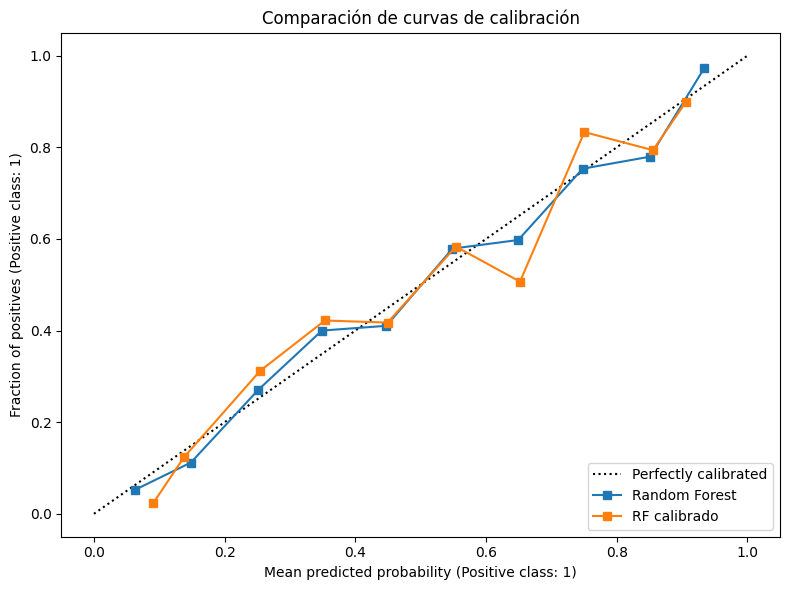

In [ ]:
import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(8, 6))

CalibrationDisplay.from_predictions(y_test,p_rf,n_bins=10,strategy="uniform",name="Random Forest",ax=ax)

CalibrationDisplay.from_predictions(y_test,p_cal,n_bins=10,strategy="uniform",name="RF calibrado",ax=ax)

ax.set_title("Comparación de curvas de calibración")
plt.tight_layout()
plt.show()

### Evaluación de la calibración sigmoidal

Se ha aplicado una calibración sigmoidal (método de Platt) al modelo Random Forest utilizando un conjunto de datos independiente del entrenamiento y de la evaluación final.

Los resultados obtenidos son:

| Métrica | Random Forest | Random Forest calibrado |
|---|---:|---:|
| Brier Score | 0.1672 | 0.1688 |
| Log Loss | 0.5001 | 0.5067 |
| ROC-AUC | 0.8189 | 0.8189 |

Se observa que el Brier Score y el Log Loss empeoran ligeramente después de la calibración, mientras que el ROC-AUC permanece prácticamente constante.

Este comportamiento es coherente con la naturaleza de la transformación sigmoidal: al ser monótona creciente cuando su pendiente es positiva, conserva el orden relativo de las predicciones y, por tanto, la capacidad de discriminación del modelo.

Los resultados muestran que la calibración no garantiza una mejora de las probabilidades estimadas. En este experimento, el método aplicado no ha conseguido mejorar las métricas evaluadas.

Será necesario complementar este análisis mediante curvas de calibración para determinar si existe un problema de calibración que la transformación sigmoidal no haya conseguido corregir.

Vamos a usar una calibración isotónica no impone una transformación sigmoidal. Aprende una función monótona más flexible a partir de los datos.

Brier: 0.16870430050651625
Log Loss: 0.5352536803735587
ROC-AUC: 0.8160600664967679


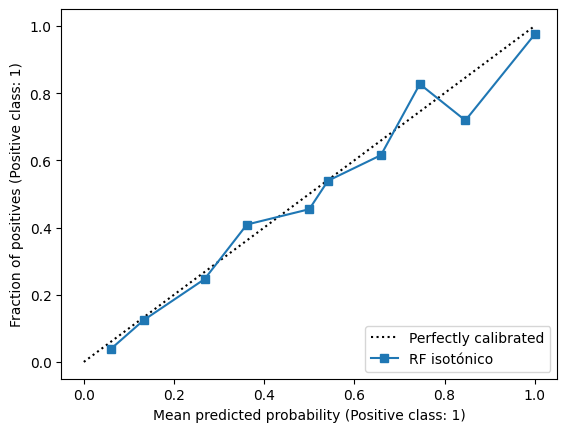

In [ ]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator

modelo_isotonico = CalibratedClassifierCV(estimator=FrozenEstimator(modelo),method="isotonic")

modelo_isotonico.fit(X_cal, y_cal)

p_iso = modelo_isotonico.predict_proba(X_test)[:, 1]
print("Brier:", brier_score_loss(y_test, p_iso))
print("Log Loss:", log_loss(y_test, p_iso))
print("ROC-AUC:", roc_auc_score(y_test, p_iso))
CalibrationDisplay.from_predictions(y_test,p_iso,n_bins=10,name="RF isotónico")

### Comparación de métodos de calibración

Se han evaluado dos métodos de calibración de probabilidades sobre un modelo Random Forest: calibración sigmoidal (Platt) y calibración isotónica.

Los resultados muestran que ninguno de los dos métodos ha conseguido mejorar las métricas del modelo original.

El Random Forest sin calibrar obtiene un Brier Score de 0.1672 y un Log Loss de 0.5001, frente a 0.1688 y 0.5067 para el método sigmoidal, y 0.1687 y 0.5353 para el isotónico.

El ROC-AUC permanece prácticamente constante con la calibración sigmoidal y disminuye ligeramente con la isotónica.

Estos resultados muestran que la aplicación de técnicas de calibración no garantiza una mejora del rendimiento probabilístico. La eficacia de cada método depende de las características del modelo original y de la información disponible para ajustar el calibrador.

Se plantea como siguiente experimento estudiar la influencia del tamaño del conjunto de calibración sobre los resultados obtenidos.

In [ ]:

import numpy as np
import pandas as pd

from scipy.special import logit

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression



def comparar_calibracion(
    y_cal,
    p_cal,
    y_test,
    p_test,
    tamaños,
    random_state=42
):
    """
    Compara Random Forest original, calibración sigmoidal
    y calibración isotónica para distintos tamaños muestrales.

    Devuelve un DataFrame con Brier, Log Loss y ROC-AUC.
    """

    y_cal = np.asarray(y_cal)
    p_cal = np.asarray(p_cal, dtype=float)
    y_test = np.asarray(y_test)
    p_test = np.asarray(p_test, dtype=float)

    if len(y_cal) != len(p_cal):
        raise ValueError("Dimensiones incompatibles en calibración")

    if len(y_test) != len(p_test):
        raise ValueError("Dimensiones incompatibles en prueba")

    if not np.all(np.isin(y_cal, [0, 1])):
        raise ValueError("Las etiquetas deben ser binarias")

    if not np.all(np.isin(y_test, [0, 1])):
        raise ValueError("Las etiquetas deben ser binarias")

    if np.any((p_cal < 0) | (p_cal > 1)):
        raise ValueError("Probabilidades fuera de [0,1]")

    if np.any((p_test < 0) | (p_test > 1)):
        raise ValueError("Probabilidades fuera de [0,1]")

    if len(np.unique(y_test)) != 2:
        raise ValueError("El test debe contener ambas clases")

    rng = np.random.default_rng(random_state)

    resultados = []

    # Referencia: Random Forest original
    resultados.append({
        "n_cal": 0,
        "metodo": "Original",
        "brier": brier_score_loss(y_test, p_test),
        "log_loss": log_loss(y_test, p_test),
        "roc_auc": roc_auc_score(y_test, p_test)
    })

    for n in tamaños:

        if n < 2 or n > len(y_cal):
            raise ValueError(
                f"Tamaño {n} no válido para calibración"
            )

        indices = rng.choice(
            len(y_cal),
            size=n,
            replace=False
        )

        yc = y_cal[indices]
        pc = p_cal[indices]

        if len(np.unique(yc)) != 2:
            raise ValueError(
                f"El subconjunto de tamaño {n} "
                "no contiene ambas clases"
            )

        # Calibración sigmoidal (Platt)
        eps = 1e-7
        pc_logit = logit(np.clip(pc, eps, 1-eps))
        pt_logit = logit(np.clip(p_test, eps, 1-eps))

        sigmoidal = LogisticRegression(
            C=1e6,
            solver="lbfgs",
            max_iter=2000
        )

        sigmoidal.fit(pc_logit.reshape(-1, 1), yc)

        p_sig = sigmoidal.predict_proba(
            pt_logit.reshape(-1, 1)
        )[:, 1]

        # Calibración isotónica
        isotonic = IsotonicRegression(
            out_of_bounds="clip"
        )

        isotonic.fit(pc, yc)

        p_iso = isotonic.predict(p_test)

        # Guardar resultados
        for nombre, probabilidades in [
            ("Sigmoidal", p_sig),
            ("Isotónica", p_iso)
        ]:

            resultados.append({
                "n_cal": n,
                "metodo": nombre,
                "brier": brier_score_loss(
                    y_test, probabilidades
                ),
                "log_loss": log_loss(
                    y_test, probabilidades
                ),
                "roc_auc": roc_auc_score(
                    y_test, probabilidades
                )
            })

    return pd.DataFrame(resultados)


In [ ]:
# Probabilidades del modelo original
p_cal = modelo.predict_proba(X_cal)[:, 1]
p_test = modelo.predict_proba(X_test)[:, 1]

resultados = comparar_calibracion(
    y_cal,
    p_cal,
    y_test,
    p_test,
    tamaños=(200, 500, 1000)
)

print(resultados)

   n_cal     metodo     brier  log_loss   roc_auc
0      0   Original  0.167239  0.500146  0.818855
1    200  Sigmoidal  0.170280  0.508993  0.818855
2    200  Isotónica  0.172413  1.047579  0.812866
3    500  Sigmoidal  0.167162  0.500028  0.818855
4    500  Isotónica  0.166821  0.535470  0.817488
5   1000  Sigmoidal  0.167175  0.500287  0.818855
6   1000  Isotónica  0.168704  0.535254  0.816060


In [ ]:

import numpy as np
import pandas as pd

from scipy.special import logit

from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

from sklearn.metrics import (
    brier_score_loss,
    log_loss,
    roc_auc_score
)


def comparar_calibracion_repetida(
    y_cal,
    p_cal,
    y_test,
    p_test,
    tamaños,
    repeticiones=30,
    random_state=42
):

    y_cal = np.asarray(y_cal)
    p_cal = np.asarray(p_cal)
    y_test = np.asarray(y_test)
    p_test = np.asarray(p_test)

    rng = np.random.default_rng(random_state)

    resultados = []

    eps = 1e-7

    # Referencia: modelo original
    resultados.append({
        "n_cal": 0,
        "metodo": "Original",
        "brier": brier_score_loss(y_test, p_test),
        "log_loss": log_loss(y_test, p_test),
        "roc_auc": roc_auc_score(y_test, p_test)
    })

    for n in tamaños:

        if n > len(y_cal):
            raise ValueError("Tamaño superior a muestra disponible")

        for repeticion in range(repeticiones):

            # Selección aleatoria de observaciones
            indices = rng.choice(
                len(y_cal),
                size=n,
                replace=False
            )

            yc = y_cal[indices]
            pc = p_cal[indices]

            if len(np.unique(yc)) < 2:
                continue

            # Transformación logit
            pc_logit = logit(
                np.clip(pc, eps, 1-eps)
            )

            pt_logit = logit(
                np.clip(p_test, eps, 1-eps)
            )

            # Calibración sigmoidal
            sigmoidal = LogisticRegression(
                C=1e6,
                max_iter=2000
            )

            sigmoidal.fit(
                pc_logit.reshape(-1, 1),
                yc
            )

            p_sig = sigmoidal.predict_proba(
                pt_logit.reshape(-1, 1)
            )[:, 1]

            # Calibración isotónica
            isotonic = IsotonicRegression(
                out_of_bounds="clip"
            )

            isotonic.fit(pc, yc)

            p_iso = isotonic.predict(p_test)

            # Evaluación de ambos métodos
            for nombre, probabilidades in [
                ("Sigmoidal", p_sig),
                ("Isotónica", p_iso)
            ]:

                resultados.append({
                    "n_cal": n,
                    "repeticion": repeticion,
                    "metodo": nombre,
                    "brier": brier_score_loss(
                        y_test, probabilidades
                    ),
                    "log_loss": log_loss(
                        y_test, probabilidades
                    ),
                    "roc_auc": roc_auc_score(
                        y_test, probabilidades
                    )
                })

    df = pd.DataFrame(resultados)

    # Agrupación y cálculo de estadísticos
    resumen = (
        df[df["metodo"] != "Original"]
        .groupby(["n_cal", "metodo"])
        [["brier", "log_loss", "roc_auc"]]
        .agg(["mean", "std"])
    )

    return df, resumen


In [ ]:
resultados, resumen = comparar_calibracion_repetida(
    y_cal,
    p_cal,
    y_test,
    p_test,
    tamaños=(200, 500, 1000),
    repeticiones=30,
    random_state=42
)

print(resumen)

                    brier            log_loss             roc_auc          
                     mean       std      mean       std      mean       std
n_cal metodo                                                               
200   Isotónica  0.173092  0.002009  0.727221  0.237299  0.812664  0.002742
      Sigmoidal  0.168661  0.001439  0.504586  0.004038  0.818855  0.000000
500   Isotónica  0.169690  0.001412  0.554505  0.031414  0.814971  0.002455
      Sigmoidal  0.167397  0.000261  0.500969  0.000969  0.818855  0.000000
1000  Isotónica  0.168704  0.000000  0.535254  0.000000  0.816060  0.000000
      Sigmoidal  0.167175  0.000000  0.500287  0.000000  0.818855  0.000000


### Análisis de estabilidad según el tamaño muestral

Para estudiar la estabilidad de los métodos de calibración, repetimos 30 veces los experimentos para cada tamaño de muestra: 200, 500 y 1.000 observaciones.

En cada repetición se selecciona aleatoriamente un subconjunto del conjunto de calibración, manteniendo fijo el conjunto de prueba.

Los resultados muestran que la calibración sigmoidal obtiene mejores valores medios de Brier Score y Log Loss para los tres tamaños muestrales estudiados.

La calibración isotónica presenta una mayor variabilidad, especialmente en Log Loss cuando se utilizan 200 observaciones. Este comportamiento puede estar relacionado con la aparición de probabilidades extremas, que reciben penalizaciones elevadas cuando se asignan a resultados incorrectos.

Por otra parte, el ROC-AUC de la calibración sigmoidal permanece constante debido a que la transformación monótona conserva el orden de las predicciones. La calibración isotónica puede introducir empates y modificar ligeramente esta métrica.

En conjunto, los resultados sugieren que, para el Random Forest y el mecanismo generador considerados, la calibración sigmoidal ofrece un comportamiento más favorable que la isotónica con los tamaños muestrales analizados.

Estos resultados son específicos del experimento y no permiten establecer una superioridad universal de un método sobre el otro.